In [1]:
import pandas as pd

df = pd.read_csv("questions.csv")
print(df.shape)
print(df.columns.tolist())
df.head(3)

FileNotFoundError: [Errno 2] No such file or directory: 'questions.csv'

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\HP\Downloads\archive\questions.csv")
print(df.shape)
print(df.columns.tolist())
df.head(3)

(1474, 13)
['QCode', 'Title', 'link', 'level', 'statement', 'Author', 'Tester', 'Editorial', 'Tags', 'Date Added', 'Time Limit', 'Source Limit', 'Languages']


,QCode,Title,link,level,statement,Author,Tester,Editorial,Tags,Date Added,Time Limit,Source Limit,Languages
0,SEQUENCE,Integer Sequences,/problems/SEQUENCE,medium,\nAll submissions for this problem are availab...,friggstad,pieguy,http://discuss.codechef.com/problems/SEQUENCE,"['friggstad', 'cook07', 'medium']",30-01-2011</td> <,4 sec</td> <,50000 Bytes</td> <,"<td>ADA, ASM, BASH, BF, C, C99 str..."
1,CHEFTEAM,Chef team,/problems/CHEFTEAM,easy,\nAll submissions for this problem are availab...,anton_lunyov,friggstad,http://discuss.codechef.com/problems/CHEFTEAM,"['anton_lunyov', 'cook06', 'easy']",14-01-2011</td> <,1 sec</td> <,50000 Bytes</td> <,"<td>ADA, ASM, BASH, BF, C, C99 str..."
2,SEATR,Sereja and Tree,/problems/SEATR,medium,\nAll submissions for this problem are availab...,sereja,iscsi,http://discuss.codechef.com/problems/SEATR,"['mathematics', 'sereja', 'dynamic-prog', 'mem...",6-11-2015</td> <,10 sec</td> <,50000 Bytes</td> <,"<td>ADA, ASM, BASH, BF, C, C99 str..."


In [4]:
print(df.isna().sum())
print()
print("Duplicate titles:", df["Title"].duplicated().sum())
print("Duplicate statements:", df["statement"].duplicated().sum())
print()
print(df["level"].value_counts())
print()
print(df["statement"].str.len().describe())
print()
print(df["statement"][0])

QCode             0
Title             0
link              0
level             0
statement         0
Author            5
Tester          408
Editorial       248
Tags              0
Date Added        5
Time Limit        5
Source Limit      5
Languages         5
dtype: int64

Duplicate titles: 18
Duplicate statements: 44

level
medium       507
easy         478
hard         290
challenge    100
beginner      99
Name: count, dtype: int64

count     1474.000000
mean      2202.842605
std       1412.394153
min        128.000000
25%       1361.500000
50%       1893.500000
75%       2609.000000
max      16837.000000
Name: statement, dtype: float64


All submissions for this problem are available.

For a fixed integer n, let x1, x2, ..., x2n be a sequence that contains each of the 2n different n bit integers exactly once. To be precise, we say an integer is an n bit integer if it can be expressed in binary with exactly n bits (with, perhaps, some leading zeros). We say the sequence is gradual if

In [5]:
import re

def clean_statement(text):
    # 1. remove the boilerplate line
    text = text.replace("All submissions for this problem are available.", "")
    # 2. cut off the Example section (sample input/output)
    text = re.split(r"\n\s*Examples?\s*\n", text, maxsplit=1)[0]
    # 3. turn all extra spaces and new lines into single spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["statement"].apply(clean_statement)

# remove duplicate problems
before = len(df)
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)
print("Problems before:", before, "-> after:", len(df))

# check for suspiciously short texts
print("Very short texts (under 200 characters):", (df["clean_text"].str.len() < 200).sum())

# save the cleaned data so we don't have to redo this
df.to_csv(r"C:\Users\HP\Downloads\archive\clean_questions.csv", index=False)

print()
print(df["clean_text"][0][:700])

Problems before: 1474 -> after: 1430
Very short texts (under 200 characters): 6

For a fixed integer n, let x1, x2, ..., x2n be a sequence that contains each of the 2n different n bit integers exactly once. To be precise, we say an integer is an n bit integer if it can be expressed in binary with exactly n bits (with, perhaps, some leading zeros). We say the sequence is gradual if two consecutive numbers differ in exactly one bit when written in binary and the first and last numbers also differ in exactly one bit in their binary representations. Your job is to generate such a sequence. This is normally a fairly standard exercise, but there is one extra constraint. For some reason, there are two particular n bit numbers a and b such that it is illegal to have a and b appe


In [6]:
import ast
from collections import Counter

# 1. the 6 very short problems
short = df[df["clean_text"].str.len() < 200]
for i, row in short.iterrows():
    print(row["Title"], "->", row["clean_text"])
    print("---")

# 2. does any text still contain a leftover Example section?
print("Still contain 'Input:' :", df["clean_text"].str.contains("Input:").sum())

# 3. turn the Tags text into a real list and count the most common tags
df["tag_list"] = df["Tags"].apply(ast.literal_eval)
counts = Counter(tag for tags in df["tag_list"] for tag in tags)
print()
print("Total different tags:", len(counts))
print(counts.most_common(60))

Stepping Up -> Statement Given a directed graph G with N vertices and M edges. For each vertex u, you must assign positive integer F(u) such that:
---
A Very Easy Problem! -> Input There's no input. Output Output some form of these numbers: 137, 1315, 73, 136, 255, 1384, 16385, one per line in the listed order.
---
Life, the Universe, and Everything -> For help on this problem, please check out our tutorial Input and Output (I/O)
---
Number Mirror -> Problem Statement Write a program that accepts a number and outputs the same. Sample Input 123 Sample Output 123
---
Money Matters -> The Government of Byteland has decide to issue new currency notes with special protection features to so as to commemorate a great mathematician.
---
Lack of Logic -> Consider the following dialog. - Father, what is the lack of logic?- Bunny.- Where? - Day.
---
Still contain 'Input:' : 64

Total different tags: 718
[('easy', 249), ('medium', 242), ('hard', 179), ('admin', 145), ('cakewalk', 121), ('simple', 

In [7]:
# 1. cut off any leftover sample input text
def cut_samples(text):
    return re.split(r"(?:Sample Input|SAMPLE INPUT|Example Input)", text, maxsplit=1)[0].strip()

df["clean_text"] = df["clean_text"].apply(cut_samples)

# 2. drop the very short, broken problems
df = df[df["clean_text"].str.len() >= 200].reset_index(drop=True)
print("Problems now:", len(df))

# 3. keep only real topic tags, and merge the duplicates
topic_map = {
    "dp": "dynamic-programming", "dynamic-prog": "dynamic-programming",
    "dynamic-programming": "dynamic-programming",
    "greedy": "greedy",
    "maths": "math", "math": "math", "simple-math": "math",
    "combinatorics": "combinatorics",
    "segment-tree": "segment-tree",
    "graph": "graph", "bfs": "graph", "dfs": "graph",
    "sorting": "sorting",
    "geometry": "geometry",
    "binary-search": "binary-search",
    "number-theory": "number-theory",
    "data-structure": "data-structures",
    "strings": "strings", "string": "strings",
    "bit": "bit-manipulation",
    "matrix-expo": "matrix-exponentiation",
    "probability": "probability",
    "implementation": "implementation",
    "ad-hoc": "ad-hoc",
}

df["topics"] = df["tag_list"].apply(
    lambda tags: sorted({topic_map[t.lower()] for t in tags if t.lower() in topic_map})
)

has_topic = (df["topics"].str.len() > 0).sum()
print("Problems with at least one topic tag:", has_topic, "of", len(df))
print()
print(Counter(t for ts in df["topics"] for t in ts).most_common())

# save again
df.to_csv(r"C:\Users\HP\Downloads\archive\clean_questions.csv", index=False)

Problems now: 1424
Problems with at least one topic tag: 620 of 1424

[('dynamic-programming', 139), ('math', 104), ('ad-hoc', 91), ('graph', 66), ('greedy', 64), ('segment-tree', 45), ('combinatorics', 45), ('sorting', 36), ('strings', 30), ('geometry', 29), ('implementation', 27), ('binary-search', 24), ('number-theory', 21), ('data-structures', 20), ('bit-manipulation', 19), ('matrix-exponentiation', 15), ('probability', 14)]


In [8]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

# --- Method 1: TF-IDF (matches on words) ---
tfidf = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(df["clean_text"])

# --- Method 2: Sentence-BERT (matches on meaning) ---
model = SentenceTransformer("all-MiniLM-L6-v2")
model.max_seq_length = 512          # read longer problem statements
emb = model.encode(df["clean_text"].tolist(), batch_size=32,
                   show_progress_bar=True, normalize_embeddings=True)
np.save(r"C:\Users\HP\Downloads\archive\embeddings.npy", emb)
print("Embeddings shape:", emb.shape)

# --- Search functions ---
def search_semantic(query, k=5):
    q = model.encode([query], normalize_embeddings=True)[0]
    scores = emb @ q
    top = scores.argsort()[::-1][:k]
    return df.iloc[top][["Title", "level", "topics"]].assign(score=scores[top].round(3))

def search_tfidf(query, k=5):
    q = tfidf.transform([query])
    scores = (tfidf_matrix @ q.T).toarray().ravel()
    top = scores.argsort()[::-1][:k]
    return df.iloc[top][["Title", "level", "topics"]].assign(score=scores[top].round(3))

query = "Count the number of ways to climb a staircase taking either 1 or 2 steps at a time"
print("SEMANTIC:");  print(search_semantic(query))
print("\nTF-IDF:");  print(search_tfidf(query))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/45 [00:00<?, ?it/s]

Embeddings shape: (1424, 384)
SEMANTIC:
                       Title     level     topics  score
206         Stepping Numbers      hard         []  0.468
1004           Robot Movings      easy         []  0.453
1162  Skyscraper Equilibrium      easy         []  0.401
803        Mountain Holidays    medium  [strings]  0.398
731    Count Steps in Matrix  beginner         []  0.378

TF-IDF:
                    Title   level           topics  score
290       Climbing Stairs    easy  [combinatorics]  0.204
803     Mountain Holidays  medium        [strings]  0.139
343  The Uncountable Ways  medium  [combinatorics]  0.131
1               Chef team    easy               []  0.127
135        Number of Ways  medium  [combinatorics]  0.107


In [9]:
# shorter version of each problem: title + first 120 words
df["short_text"] = df.apply(
    lambda r: r["Title"] + ". " + " ".join(r["clean_text"].split()[:120]), axis=1
)
emb_short = model.encode(df["short_text"].tolist(), batch_size=32,
                         show_progress_bar=True, normalize_embeddings=True)
np.save(r"C:\Users\HP\Downloads\archive\embeddings_short.npy", emb_short)

def search_emb(matrix, query, k=5):
    q = model.encode([query], normalize_embeddings=True)[0]
    scores = matrix @ q
    top = scores.argsort()[::-1][:k]
    return df.iloc[top][["Title", "level", "topics"]].assign(score=scores[top].round(3))

queries = [
    "Count the number of ways to climb a staircase taking either 1 or 2 steps at a time",
    "Find the shortest path between two cities in a weighted road network",
    "Given an array, answer many range sum queries with updates in between",
]

for q in queries:
    print("\n=== QUERY:", q)
    print("\n-- Full text embedding");  print(search_emb(emb, q, 3)[["Title", "score"]])
    print("\n-- Short text embedding"); print(search_emb(emb_short, q, 3)[["Title", "score"]])
    print("\n-- TF-IDF");               print(search_tfidf(q, 3)[["Title", "score"]])

Batches:   0%|          | 0/45 [00:00<?, ?it/s]


=== QUERY: Count the number of ways to climb a staircase taking either 1 or 2 steps at a time

-- Full text embedding
                       Title  score
206         Stepping Numbers  0.468
1004           Robot Movings  0.453
1162  Skyscraper Equilibrium  0.401

-- Short text embedding
                      Title  score
731   Count Steps in Matrix  0.507
1330         The Dirty Path  0.503
135          Number of Ways  0.496

-- TF-IDF
                    Title  score
290       Climbing Stairs  0.204
803     Mountain Holidays  0.139
343  The Uncountable Ways  0.131

=== QUERY: Find the shortest path between two cities in a weighted road network

-- Full text embedding
                     Title  score
607               Highways  0.514
784  Shortest path queries  0.505
123              Festivals  0.505

-- Short text embedding
                                          Title  score
784                       Shortest path queries  0.603
1042                         Chef Travel Routes  0.56

In [10]:
def minmax(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-9)

def search_hybrid(query, k=5, alpha=0.5):
    # semantic score (meaning)
    q_emb = model.encode([query], normalize_embeddings=True)[0]
    sem = emb_short @ q_emb
    # keyword score (words)
    kw = (tfidf_matrix @ tfidf.transform([query]).T).toarray().ravel()
    # combine: alpha = weight on meaning, (1 - alpha) = weight on keywords
    score = alpha * minmax(sem) + (1 - alpha) * minmax(kw)
    top = score.argsort()[::-1][:k]
    return df.iloc[top][["Title", "level", "topics"]].assign(score=score[top].round(3))

for q in queries:
    print("\n=== QUERY:", q)
    print(search_hybrid(q, 5)[["Title", "topics", "score"]])


=== QUERY: Count the number of ways to climb a staircase taking either 1 or 2 steps at a time
                     Title                                topics  score
803      Mountain Holidays                             [strings]  0.762
135         Number of Ways                       [combinatorics]  0.751
290        Climbing Stairs                       [combinatorics]  0.748
852          Knight Moving  [dynamic-programming, number-theory]  0.704
731  Count Steps in Matrix                                    []  0.683

=== QUERY: Find the shortest path between two cities in a weighted road network
                                          Title                        topics  \
1123  Three-Degree-Bounded Maximum Cost Subtree         [dynamic-programming]   
1258                     Queries on tree again!          [math, segment-tree]   
607                                    Highways                            []   
784                       Shortest path queries  [dynamic-programmin

In [11]:
sharp = {"dynamic-programming", "graph", "greedy", "segment-tree", "combinatorics",
         "sorting", "strings", "geometry", "binary-search", "number-theory",
         "data-structures", "bit-manipulation", "matrix-exponentiation", "probability"}

st = [set(ts) & sharp for ts in df["topics"]]
labeled = [i for i in range(len(df)) if st[i]]
print("Problems used for evaluation:", len(labeled))

# similarity of every problem to every other problem
def prep(m):
    m = np.array(m, dtype=float)
    np.fill_diagonal(m, np.nan)          # a problem must not match itself
    return m

def rownorm(m):
    mn = np.nanmin(m, axis=1, keepdims=True)
    mx = np.nanmax(m, axis=1, keepdims=True)
    return (m - mn) / (mx - mn + 1e-9)

S = {
    "TF-IDF": prep((tfidf_matrix @ tfidf_matrix.T).toarray()),
    "Embedding (full text)": prep(emb @ emb.T),
    "Embedding (short text)": prep(emb_short @ emb_short.T),
}
for a in [0.3, 0.5, 0.7]:
    S[f"Hybrid (alpha={a})"] = a * rownorm(S["Embedding (short text)"]) + (1 - a) * rownorm(S["TF-IDF"])

def evaluate(sim, k=5):
    prec, rr = [], []
    for i in labeled:
        row = np.nan_to_num(sim[i], nan=-np.inf)
        order = np.argsort(row)[::-1][:50]
        rel = [bool(st[j] & st[i]) for j in order]
        prec.append(np.mean(rel[:k]))
        rr.append(1 / (rel.index(True) + 1) if True in rel else 0)
    return round(np.mean(prec), 3), round(np.mean(rr), 3)

results = pd.DataFrame(
    {name: evaluate(sim) for name, sim in S.items()},
    index=["Precision@5", "MRR"]
).T
print(results)

Problems used for evaluation: 474
                        Precision@5    MRR
TF-IDF                        0.125  0.270
Embedding (full text)         0.154  0.316
Embedding (short text)        0.141  0.300
Hybrid (alpha=0.3)            0.138  0.283
Hybrid (alpha=0.5)            0.139  0.290
Hybrid (alpha=0.7)            0.144  0.296


In [12]:
# 1. random baseline: chance that a random other problem shares a sharp tag
chance = []
for i in labeled:
    shares = sum(1 for j in range(len(df)) if j != i and (st[j] & st[i]))
    chance.append(shares / (len(df) - 1))
print("Random baseline Precision@5:", round(np.mean(chance), 3))

# 2. per-topic Precision@5 for the best method so far
def per_topic(sim, k=5):
    out = {}
    for t in sorted(sharp):
        idx = [i for i in labeled if t in st[i]]
        p = []
        for i in idx:
            row = np.nan_to_num(sim[i], nan=-np.inf)
            order = np.argsort(row)[::-1][:k]
            p.append(np.mean([t in st[j] for j in order]))
        out[t] = (len(idx), round(np.mean(p), 3))
    return pd.DataFrame(out, index=["n_problems", "Precision@5 (same topic)"]).T

print()
print("Embedding (full text):");  print(per_topic(S["Embedding (full text)"]))
print()
print("TF-IDF:");                 print(per_topic(S["TF-IDF"]))

Random baseline Precision@5: 0.054

Embedding (full text):
                       n_problems  Precision@5 (same topic)
binary-search                24.0                     0.050
bit-manipulation             19.0                     0.021
combinatorics                45.0                     0.089
data-structures              20.0                     0.070
dynamic-programming         139.0                     0.168
geometry                     29.0                     0.234
graph                        66.0                     0.109
greedy                       64.0                     0.109
matrix-exponentiation        15.0                     0.000
number-theory                21.0                     0.114
probability                  14.0                     0.071
segment-tree                 45.0                     0.213
sorting                      36.0                     0.028
strings                      30.0                     0.260

TF-IDF:
                       n_problem

In [ ]:
model2 = SentenceTransformer("all-mpnet-base-v2")
model2.max_seq_length = 384
emb2 = model2.encode(df["clean_text"].tolist(), batch_size=16,
                     show_progress_bar=True, normalize_embeddings=True)
np.save(r"C:\Users\HP\Downloads\archive\embeddings_mpnet.npy", emb2)

S["Embedding mpnet (full text)"] = prep(emb2 @ emb2.T)
print(evaluate(S["Embedding mpnet (full text)"]))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--sentence-transformers--all-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

In [1]:
sol = pd.read_csv(r"C:\Users\HP\Downloads\archive\solutions.csv", nrows=5)
print(sol.columns.tolist())
print(sol.head(3))

NameError: name 'pd' is not defined

In [2]:
import pandas as pd

sol = pd.read_csv(r"C:\Users\HP\Downloads\archive\solutions.csv", nrows=5)
print(sol.columns.tolist())
print(sol.head(3))

['QCode', 'SolutionID', 'timeago', 'UserID', 'Status', 'TimeTaken', 'MemTaken', 'Language', 'SolutionUrl']
  QCode SolutionID            timeago              UserID        Status  \
0    A1  S11986970  07:58 PM 31/10/16  /users/ismail_2311      accepted   
1    A1  S11990433  07:51 PM 01/11/16     /users/mohit_15  wrong answer   
2    A1  S11990440  07:54 PM 01/11/16     /users/mohit_15      accepted   

  TimeTaken MemTaken Language              SolutionUrl  
0      1.43       2M        C  /viewplaintext/11986970  
1      0.00       2M        C  /viewplaintext/11990433  
2      0.00       2M        C  /viewplaintext/11990440  


In [3]:
import os

folder = r"C:\Users\HP\Downloads\archive\program_codes"
items = os.listdir(folder)
print("Number of items:", len(items))
print(items[:10])

# peek inside the first item
first = os.path.join(folder, items[0])
if os.path.isdir(first):
    print("It's a folder. Inside:", os.listdir(first)[:10])
else:
    print(open(first, errors="ignore").read()[:600])

Number of items: 4
['first.csv', 'program_codes', 'second.csv', 'third.csv']
SolutionID,Solutions
S12111596,"
    #include<iostream>
    using namespace std;
    int main()
    {
    int i,t,temp,k;
    cin>>t;
    while(t--)
    {
    cin>>k;
    int a[k];
    for(i=0;i<k;i++)
    cin>>a[i];
    temp=1-a[0];
    for(i=1;i<k;i++)
    {
    temp=2*temp;
    temp=temp-a[i];
    }
    if(temp==0)
    cout<<""Yes"";
    else
    cout<<""No"";
    }
    return 0;
    } 
    

"
S12111584,"
    #include<iostream>
    using namespace std;
    int main()
    {
    int i,t,temp,k;
    cin>>t;
    while(t--)
    {
    cin>>k;
    int a[k];
    for(i=0;i<n;i++)
    cin>>a[i];
   


In [4]:
import os, pandas as pd

folder = r"C:\Users\HP\Downloads\archive\program_codes"
for f in ["first.csv", "second.csv", "third.csv"]:
    print(f, round(os.path.getsize(os.path.join(folder, f)) / 1e6), "MB")
print("Inside nested folder:", os.listdir(os.path.join(folder, "program_codes"))[:10])

# which solutions were accepted, and for how many problems
sol = pd.read_csv(r"C:\Users\HP\Downloads\archive\solutions.csv")
acc = sol[sol["Status"] == "accepted"]
print("Total submissions:", len(sol))
print("Accepted:", len(acc), "| problems with at least one accepted:", acc["QCode"].nunique())
print(acc["Language"].value_counts().head(6))

first.csv 485 MB
second.csv 424 MB
third.csv 285 MB
Inside nested folder: ['first.csv', 'second.csv', 'third.csv']
Total submissions: 637763
Accepted: 145394 | problems with at least one accepted: 339
Language
C            40680
C++ 4.3.2    28925
C++ 4.9.2    26829
JAVA         15700
C++14        11767
C++ 4.8.1     7674
Name: count, dtype: int64


In [6]:
import ast, numpy as np, pandas as pd
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

base = r"C:\Users\HP\Downloads\archive"
df = pd.read_csv(base + r"\clean_questions.csv")
df["topics"] = df["topics"].apply(ast.literal_eval)
df["tag_list"] = df["tag_list"].apply(ast.literal_eval)
df["short_text"] = df.apply(
    lambda r: r["Title"] + ". " + " ".join(r["clean_text"].split()[:120]), axis=1)

emb = np.load(base + r"\embeddings.npy")
emb_short = np.load(base + r"\embeddings_short.npy")
print("Shapes:", df.shape, emb.shape, emb_short.shape)

tfidf = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(df["clean_text"])

model = SentenceTransformer("all-MiniLM-L6-v2")
model.max_seq_length = 512

def search_emb(matrix, query, k=5):
    q = model.encode([query], normalize_embeddings=True)[0]
    scores = matrix @ q
    top = scores.argsort()[::-1][:k]
    return df.iloc[top][["Title", "level", "topics"]].assign(score=scores[top].round(3))

print(search_emb(emb, "Find the shortest path between two cities in a weighted road network"))

Shapes: (1424, 17) (1424, 384) (1424, 384)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

                       Title   level                        topics  score
607                 Highways    hard                            []  0.514
784    Shortest path queries    hard  [dynamic-programming, graph]  0.505
123                Festivals  medium                            []  0.505
1258  Queries on tree again!    hard          [math, segment-tree]  0.504
901              Greedy Trip  medium                       [graph]  0.503


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [8, 12, 16, 20, 25, 30]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb)
    print(k, round(silhouette_score(emb, km.labels_), 4))

8 0.0321
12 0.031
16 0.022
20 0.0216
25 0.028
30 0.0216


In [8]:
k = 12
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb)
df["cluster"] = km.labels_

terms = np.array(tfidf.get_feature_names_out())
overall_mean = np.asarray(tfidf_matrix.mean(axis=0)).ravel()

for c in range(k):
    idx = np.where(df["cluster"] == c)[0]
    cluster_mean = np.asarray(tfidf_matrix[idx].mean(axis=0)).ravel()
    top_words = terms[(cluster_mean - overall_mean).argsort()[::-1][:8]]
    tags = Counter(t for ts in df.loc[idx, "topics"] for t in ts).most_common(3)
    print(f"\nCluster {c} ({len(idx)} problems)")
    print("  distinctive words:", ", ".join(top_words))
    print("  common tags:", tags)
    print("  examples:", df.loc[idx, "Title"].head(4).tolist())

df.to_csv(base + r"\clustered_questions.csv", index=False)


Cluster 0 (90 problems)
  distinctive words: nodes, tree, graph, node, edge, edges, vertices, vertex
  common tags: [('graph', 20), ('dynamic-programming', 11), ('segment-tree', 7)]
  examples: ['Sereja and Tree', 'Queries on a Binary Tree', 'Build the Tree', 'Chef And Fibonacci Tree']

Cluster 1 (173 problems)
  distinctive words: chef, subtask, points, denoting, problems, russian chef, vietnamese chef, russian
  common tags: [('dynamic-programming', 22), ('ad-hoc', 19), ('math', 15)]
  examples: ['Chef and Chain', 'Chef and Strange Operations', 'Way Out', 'Chef and Girlfriend']

Cluster 2 (104 problems)
  distinctive words: game, player, players, play, wins, turn, winner, cards
  common tags: [('dynamic-programming', 10), ('math', 9), ('combinatorics', 6)]
  examples: ['Fit to Play', 'Chef Game', 'The White Knight', 'Chef and A Large Permutation']

Cluster 3 (123 problems)
  distinctive words: string, strings, letters, substring, characters, length, substrings, palindrome
  common t

C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


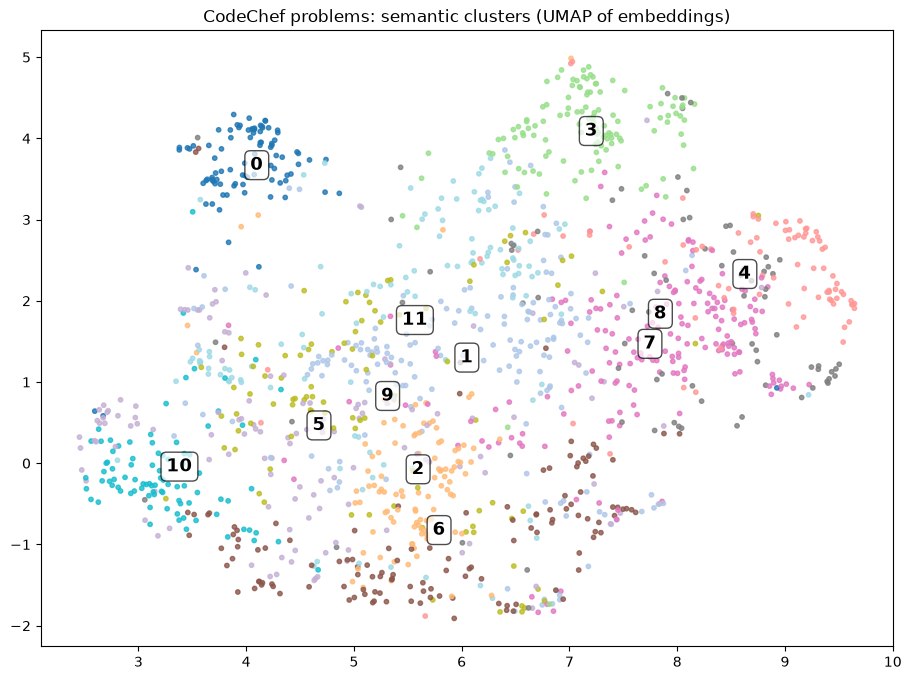

In [10]:
import matplotlib.pyplot as plt
import umap

coords = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                   random_state=42).fit_transform(emb)

plt.figure(figsize=(11, 8))
plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="tab20", s=10, alpha=0.8)
for c in range(k):
    cx, cy = coords[df["cluster"] == c].mean(axis=0)
    plt.text(cx, cy, str(c), fontsize=13, weight="bold",
             bbox=dict(facecolor="white", alpha=0.7, boxstyle="round"))
plt.title("CodeChef problems: semantic clusters (UMAP of embeddings)")
plt.savefig(base + r"\clusters.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import re

# keep the first clustering for comparison
df["cluster_v1"] = df["cluster"]

# 1. remove translation boilerplate and recurring story names
names = r"chef|chefs|chefland|sereja|devu|ciel|byteland|little elephant"
def clean2(t):
    sents = re.split(r"(?<=[.!?])\s+", t)
    sents = [s for s in sents if not re.search(
        r"mandarin|chinese|russian|vietnamese|bengali|translat|subtask", s, re.I)]
    t = " ".join(sents)
    t = re.sub(r"\b(" + names + r")\b", " ", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip()

df["clean_text2"] = df["clean_text"].apply(clean2)
print("Texts now under 100 characters:", (df["clean_text2"].str.len() < 100).sum())

# 2. re-embed
emb2 = model.encode(df["clean_text2"].tolist(), batch_size=32,
                    show_progress_bar=True, normalize_embeddings=True)
np.save(base + r"\embeddings_v2.npy", emb2)

# 3. evaluate old vs new with the same method as before
sharp = {"dynamic-programming", "graph", "greedy", "segment-tree", "combinatorics",
         "sorting", "strings", "geometry", "binary-search", "number-theory",
         "data-structures", "bit-manipulation", "matrix-exponentiation", "probability"}
st = [set(ts) & sharp for ts in df["topics"]]
labeled = [i for i in range(len(df)) if st[i]]

def evaluate(m, k=5):
    sim = m @ m.T
    np.fill_diagonal(sim, -np.inf)
    prec, rr = [], []
    for i in labeled:
        order = np.argsort(sim[i])[::-1][:50]
        rel = [bool(st[j] & st[i]) for j in order]
        prec.append(np.mean(rel[:k]))
        rr.append(1 / (rel.index(True) + 1) if True in rel else 0)
    return round(np.mean(prec), 3), round(np.mean(rr), 3)

print("(Precision@5, MRR)")
print("old embeddings:", evaluate(emb))
print("new embeddings:", evaluate(emb2))

# 4. re-cluster with the new embeddings
k = 12
km2 = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb2)
df["cluster"] = km2.labels_
tfidf2 = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
tm2 = tfidf2.fit_transform(df["clean_text2"])
terms2 = np.array(tfidf2.get_feature_names_out())
overall2 = np.asarray(tm2.mean(axis=0)).ravel()
for c in range(k):
    idx = np.where(df["cluster"] == c)[0]
    cm = np.asarray(tm2[idx].mean(axis=0)).ravel()
    words = terms2[(cm - overall2).argsort()[::-1][:8]]
    tags = Counter(t for ts in df.loc[idx, "topics"] for t in ts).most_common(3)
    print(f"\nCluster {c} ({len(idx)} problems)")
    print("  words:", ", ".join(words))
    print("  tags:", tags)
    print("  examples:", df.loc[idx, "Title"].head(4).tolist())

df.to_csv(base + r"\clustered_questions_v2.csv", index=False)

Texts now under 100 characters: 0


Batches:   0%|          | 0/45 [00:00<?, ?it/s]

(Precision@5, MRR)
old embeddings: (np.float64(0.154), np.float64(0.316))
new embeddings: (np.float64(0.123), np.float64(0.258))

Cluster 0 (98 problems)
  words: cell, cells, matrix, grid, row, columns, rows, height
  tags: [('dynamic-programming', 12), ('greedy', 6), ('implementation', 5)]
  examples: ['Little Elephant and Magic', 'Way Out', 'Block Drop', 'Head office building']

Cluster 1 (107 problems)
  words: time, minutes, server, elephants, velocity, minute, hour, password
  tags: [('ad-hoc', 10), ('math', 9), ('graph', 8)]
  examples: ['Chef and Girlfriend', 'Sereja and Data Structures', 'Password Cracking Challenge', 'Ciel and password cracking']

Cluster 2 (82 problems)
  words: points, polygon, triangle, point, coordinates, sticks, sides, plane
  tags: [('geometry', 20), ('math', 7), ('sorting', 5)]
  examples: ['The Best Box', 'Fit Squares in Triangle', 'Polygon & Circles', 'Congruent triangles']

Cluster 3 (103 problems)
  words: query, queries, array, type, query type, s

In [12]:
from sklearn.metrics import normalized_mutual_info_score

# 1. cluster quality against tags (problems with exactly one sharp tag)
single = [i for i in range(len(df)) if len(st[i]) == 1]
y = [list(st[i])[0] for i in single]
print("Cluster agreement with tags (NMI, higher = better)")
print("  old clusters:    ", round(normalized_mutual_info_score(y, df["cluster_v1"].values[single]), 3))
print("  cleaned clusters:", round(normalized_mutual_info_score(y, df["cluster"].values[single]), 3))

# 2. how often does a problem's nearest neighbour share its author?
auth = df["Author"].fillna("?").values
def same_author(m, k=5):
    sim = m @ m.T
    np.fill_diagonal(sim, -np.inf)
    top = np.argsort(sim, axis=1)[:, ::-1][:, :k]
    return round(np.mean([[auth[j] == auth[i] and auth[i] != "?" for j in top[i]]
                          for i in range(len(df))]), 3)
print("\nShare of top-5 neighbours with the same author")
print("  old embeddings:", same_author(emb))
print("  new embeddings:", same_author(emb2))

Cluster agreement with tags (NMI, higher = better)
  old clusters:     0.2
  cleaned clusters: 0.254

Share of top-5 neighbours with the same author
  old embeddings: 0.138
  new embeddings: 0.097


C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


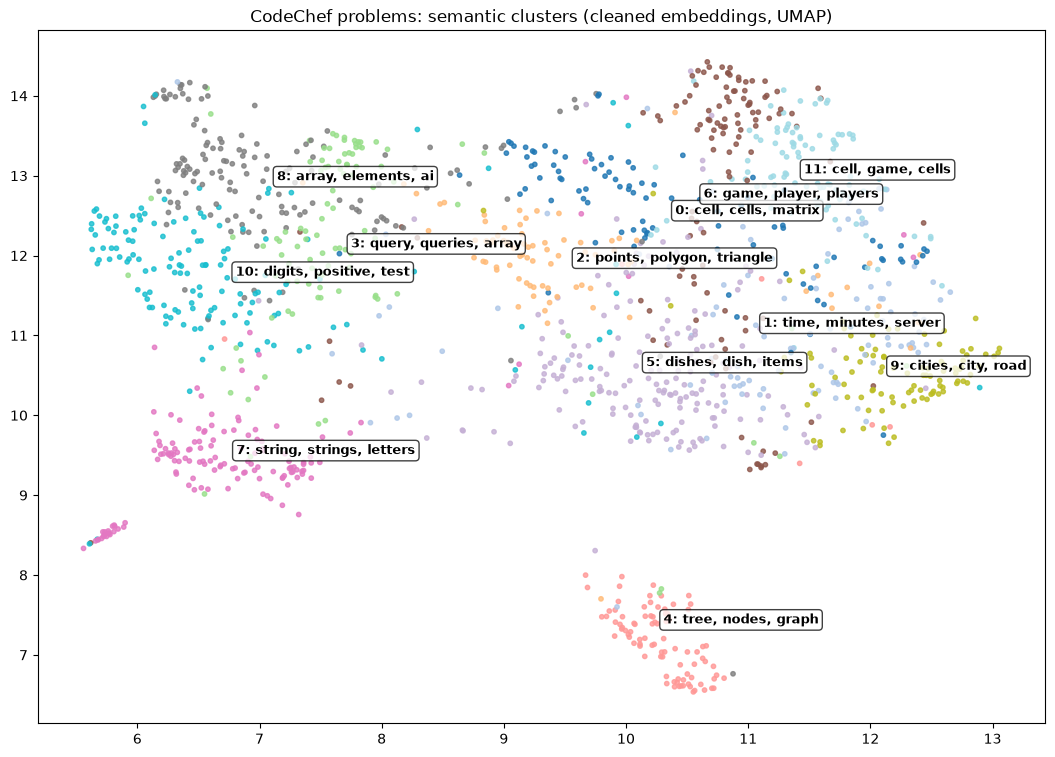

{0: 'cell, cells, matrix', 1: 'time, minutes, server', 2: 'points, polygon, triangle', 3: 'query, queries, array', 4: 'tree, nodes, graph', 5: 'dishes, dish, items', 6: 'game, player, players', 7: 'string, strings, letters', 8: 'array, elements, ai', 9: 'cities, city, road', 10: 'digits, positive, test', 11: 'cell, game, cells'}


In [13]:
import matplotlib.pyplot as plt
import umap

# auto-generated label = the 3 most distinctive words of each cluster
labels = {}
for c in range(k):
    idx = np.where(df["cluster"] == c)[0]
    cm = np.asarray(tm2[idx].mean(axis=0)).ravel()
    labels[c] = ", ".join(terms2[(cm - overall2).argsort()[::-1][:3]])

coords = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                   random_state=42).fit_transform(emb2)

plt.figure(figsize=(13, 9))
plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="tab20", s=10, alpha=0.8)
for c in range(k):
    cx, cy = coords[df["cluster"] == c].mean(axis=0)
    plt.text(cx, cy, f"{c}: {labels[c]}", fontsize=9, weight="bold",
             bbox=dict(facecolor="white", alpha=0.75, boxstyle="round"))
plt.title("CodeChef problems: semantic clusters (cleaned embeddings, UMAP)")
plt.savefig(base + r"\clusters_v2.png", dpi=150, bbox_inches="tight")
plt.show()
print(labels)

In [14]:
def find_similar(problem_text, k=5):
    q = model.encode([clean2(problem_text)], normalize_embeddings=True)[0]
    scores = emb2 @ q
    top = scores.argsort()[::-1][:k]
    out = df.iloc[top][["Title", "level", "topics", "cluster"]].copy()
    out["similarity"] = scores[top].round(3)
    return out

test = """A frog stands on stone 1 of a river with N stones in a row. In one jump it can
move to the next stone or skip one stone. Count the number of different ways the frog
can reach stone N. Since the answer can be large, print it modulo 1000000007."""

print(find_similar(test))

                                  Title   level  \
186                       Chefs new Pet    easy   
1172                     Chef and Frogs    easy   
68    Chef and Walking on the rectangle    easy   
804                          Smart Frog  medium   
985                          Chef World  medium   

                             topics  cluster  similarity  
186                              []        1       0.571  
1172          [dynamic-programming]        1       0.546  
68                         [ad-hoc]       11       0.511  
804                              []       11       0.502  
985   [math, matrix-exponentiation]        1       0.497  


In [15]:
sim_e = emb2 @ emb2.T
sim_t = (tm2 @ tm2.T).toarray()

i_idx, j_idx = np.triu_indices(len(df), k=1)
e = sim_e[i_idx, j_idx]
t = sim_t[i_idx, j_idx]

# keep pairs that share a sharp topic tag and come from different authors
auth = df["Author"].fillna("?").values
ok = np.array([bool(st[i] & st[j]) and auth[i] != auth[j] for i, j in zip(i_idx, j_idx)])

score = np.where(ok, e - t, -np.inf)
for n in np.argsort(score)[::-1][:12]:
    i, j = i_idx[n], j_idx[n]
    print(f"\n{df.Title[i]}  <->  {df.Title[j]}")
    print(f"  embedding similarity {e[n]:.2f} | word overlap {t[n]:.2f} | shared tags {st[i] & st[j]}")
    print("  A:", df.clean_text2[i][:160])
    print("  B:", df.clean_text2[j][:160])


Subarray LCM  <->  Parenthesis with Maximum Sum Subarray
  embedding similarity 0.72 | word overlap 0.03 | shared tags {'dynamic-programming'}
  A: Given an array A1,A2...AN, you have to print the size of the largest contiguous subarray such that LCM of all integers in that subarray is equal to the product 
  B: You are given a character parenthesis array and an integer array. You need to find the maximum sum sub-array in the integer array such that the corresponding su

FastFood Combos  <->  Pizza Delivery
  embedding similarity 0.71 | word overlap 0.02 | shared tags {'dynamic-programming'}
  A: Sometimes Sergey visits fast food restaurants. Today he is going to visit the one called PizzaKing. Sergey wants to buy N meals, which he had enumerated by inte
  B: Po had recently started home delivery service for pizzas. Po has only a single delivery boy that delivers the orders by riding his motorcycle. The motorcycle ha

Mountain Holidays 2  <->  Byteland Tours
  embedding similarity 0.7

In [16]:
# 1. hubness: which problems show up in many other problems' top-5 lists?
sim = emb2 @ emb2.T
np.fill_diagonal(sim, -np.inf)
top5 = np.argsort(sim, axis=1)[:, ::-1][:, :5]
counts = np.bincount(top5.ravel(), minlength=len(df))
print("Most frequent in other problems' top-5:")
for i in counts.argsort()[::-1][:8]:
    print(f"  {df.Title[i]}: {counts[i]} times")
print("Problems that never appear in anyone's top-5:", int((counts == 0).sum()))

# 2. stricter pairs: shared tag other than DP, different author, little word overlap
st2 = [s - {"dynamic-programming"} for s in st]
ok = np.array([bool(st2[i] & st2[j]) and auth[i] != auth[j] and t[n] < 0.15
               for n, (i, j) in enumerate(zip(i_idx, j_idx))])
score = np.where(ok, e, -np.inf)
for n in np.argsort(score)[::-1][:10]:
    i, j = i_idx[n], j_idx[n]
    print(f"\n{df.Title[i]}  <->  {df.Title[j]}")
    print(f"  embedding {e[n]:.2f} | word overlap {t[n]:.2f} | tags {st2[i] & st2[j]}")
    print("  A:", df.clean_text2[i][:300])
    print("  B:", df.clean_text2[j][:300])

Most frequent in other problems' top-5:
  Game of Divisors: 45 times
  Game on a Grid: 42 times
  Houses and Restaurants: 38 times
  Chef and Walking on the rectangle: 38 times
  Easy Queries: 35 times
  The Amazing All-In-One Cooking Machine - Challenge: 30 times
  Post Office: 29 times
  Lowest Sum: 28 times
Problems that never appear in anyone's top-5: 196

Roots of a Tree  <->  Tree Fun
  embedding 0.76 | word overlap 0.11 | tags {'graph'}
  A: You are given a tree with N nodes, numbered from 1 to N. You need to handle the queiries of the following two types: + x y. Add a path going from the node x to the node y (or from y to x because it's actually irrelevant). We will never add the path that is already a present one. - x y. Delete the pa
  B: David is a computer science student who loves his future profession. He is one of those who think that trees grow down, not up. David likes connected undirected acyclic graphs, also known as trees. He especially likes solving problems about 

In [17]:
variants = {
    "frog story": test,
    "same idea, neutral wording": "A person is at position 1 of a line of N positions. In one move the person goes to the next position or skips one. Count the number of ways to reach position N, modulo 1000000007.",
    "stairs wording": "Count the number of ways to climb N stairs taking 1 or 2 steps at a time, modulo 1000000007.",
}

targets = ["Climbing Stairs", "Number of Ways"]
for name, text in variants.items():
    q = model.encode([clean2(text)], normalize_embeddings=True)[0]
    order = (emb2 @ q).argsort()[::-1]
    print("\n", name)
    print("  top 5:", df.Title.iloc[order[:5]].tolist())
    for t in targets:
        i = df.index[df.Title == t][0]
        print(f"  rank of '{t}':", int(np.where(order == i)[0][0]) + 1)


 frog story
  top 5: ['Chefs new Pet', 'Chef and Frogs', 'Chef and Walking on the rectangle', 'Smart Frog', 'Chef World']
  rank of 'Climbing Stairs': 53
  rank of 'Number of Ways': 21

 same idea, neutral wording
  top 5: ['Chef World', 'Sereja and Line', 'Robot Movings', 'Little Elephant and T-Shirts', 'Chef and Numbers']
  rank of 'Climbing Stairs': 657
  rank of 'Number of Ways': 6

 stairs wording
  top 5: ['Stepping Numbers', 'Number of Ways', 'Robot Movings', 'Chef and Favourite Sequence', 'Dai Ma Chu Shi']
  rank of 'Climbing Stairs': 142
  rank of 'Number of Ways': 2


In [18]:
i = df.index[df.Title == "Climbing Stairs"][0]
print("Original text:\n", df.clean_text[i][:600])
print("\nCleaned text:\n", df.clean_text2[i][:600])
print("\nLength before/after:", len(df.clean_text[i]), len(df.clean_text2[i]))

query = "Count the number of ways to climb N stairs taking 1 or 2 steps at a time"
q_new = model.encode([clean2(query)], normalize_embeddings=True)[0]
q_old = model.encode([query], normalize_embeddings=True)[0]
for name, m, q in [("old embeddings", emb, q_old), ("cleaned embeddings", emb2, q_new)]:
    order = (m @ q).argsort()[::-1]
    print(name, "-> rank of Climbing Stairs:", int(np.where(order == i)[0][0]) + 1)

Original text:
 There is a ritual that some monks of Byteland perform every century as a sign of respect and worship towards BOOL, the God of Byteland. All the monks train for many years in order to accomplish an extremely hard task, that is the one of accessing the sacred temple of Byteland, where only the best of the bests monks are allowed to enter and worship their god, BOOL. The training the monks perform, usually consists of several physically and intellectually challenging tasks, trained and perfected over the course of many years, so that one of them can be eligible for the ultimate task that is a com

Cleaned text:
 There is a ritual that some monks of perform every century as a sign of respect and worship towards BOOL, the God of . All the monks train for many years in order to accomplish an extremely hard task, that is the one of accessing the sacred temple of , where only the best of the bests monks are allowed to enter and worship their god, BOOL. The training the monks pe